In [2]:
import numpy as np
import sionna.rt as rt
from jupyter_server.prometheus import metrics

practice_scene = rt.load_scene()

jitc_llvm_init(): LLVM API initialization failed ..


In [3]:
tx = rt.Transmitter(
    name = "test_tx",
    position = [0, 0, 2]
)

practice_scene.add(tx)

In [4]:
rx_a = rt.Receiver(
    name = "rx_a",
    position = [5, 0, 1]
)

rx_b = rt.Receiver(
    name = "rx_b",
    position = [10, 0, 1]
)

practice_scene.add(rx_a)
practice_scene.add(rx_b)

rec_a = practice_scene.get("rx_a")
rec_a.position = [7, 0, 1]

rec_b = practice_scene.get("rx_b")
practice_scene.remove(rec_b.name)

print(rx_a.position)
print(rx_a.name)
print(practice_scene.get("rx_b"))

rx_b.position = [12, 0, 1]

practice_scene.add(rx_b)

print(practice_scene.receivers.keys())
print(practice_scene.get("rx_b").position)

[[7, 0, 1]]
rx_a
None
dict_keys(['rx_a', 'rx_b'])
[[12, 0, 1]]


In [5]:
practice_scene.frequency = 3.5e9

practice_scene.tx_array = rt.PlanarArray(
    num_rows = 1,
    num_cols = 1,
    vertical_spacing = 0.5,
    horizontal_spacing = 0.5,
    pattern = "iso",
    polarization = "V"
)

practice_scene.rx_array = rt.PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization= "V"
)

practice_scene.all_set(radio_map=False)

In [6]:
practice_solver = rt.PathSolver()

practice_paths = practice_solver(
    scene = practice_scene,
    max_depth=0
)

print(list(practice_scene.receivers.keys()))
print(practice_paths.valid)
delays = np.array(practice_paths.tau)
print(delays.shape)

delays_ns = delays * 1e+9
print(delays_ns[0, 0, 0])
print(delays_ns[1, 0, 0])

['rx_a', 'rx_b']
[[[True]],
 [[True]]]
(2, 1, 1)
23.586542
40.166435


In [7]:
tx_position = np.array(practice_scene.get("test_tx").position)
rx_position = np.array(practice_scene.get("rx_a").position)

distance = np.linalg.norm(rx_position - tx_position)

delay_for_first_receiver_ns = (distance / 299_792_458) * 1e+9
print("My value:", delay_for_first_receiver_ns, ", value calculated by sionna:", delays_ns[0, 0, 0])

rx_b_position = np.array(practice_scene.get("rx_b").position)

distance_second = np.linalg.norm(rx_b_position - tx_position)

delay_for_second_receiver_ns = (distance_second / 299_792_458) * 1e+9
print("My second value:", delay_for_second_receiver_ns, ", value calculated by sionna:", delays_ns[1, 0, 0])



My value: 23.586544 , value calculated by sionna: 23.586542
My second value: 40.16644 , value calculated by sionna: 40.166435


In [8]:
first_matches = np.isclose(
    delays_ns[0, 0, 0],
    delay_for_first_receiver_ns,
    rtol = 1e-6,
    atol = 0.0
)


second_matches = np.isclose(
    delays_ns[1, 0, 0],
    delay_for_second_receiver_ns,
    rtol = 1e-6,
    atol = 0.0
)


false_second_matches = np.isclose(
    delays_ns[1, 0, 0] + 1,
    delay_for_second_receiver_ns,
    rtol = 1e-6,
    atol = 0.0
)

assert first_matches, "Затримка rx_a не збігається з еталоном"
assert second_matches, "Затримка rx_b не збігається з еталоном"

print("All reviews are done")

All reviews are done


In [11]:
practice_scene.frequency = 3.5e9

paths_35 = practice_solver(
    scene = practice_scene,
    max_depth = 0
)

a_35, tau_35 = paths_35.cir(
    normalize_delays=False,
    out_type="numpy"
)

gains_35 = np.abs(a_35) ** 2

practice_scene.frequency = 7e9

paths_7 = practice_solver(
    scene = practice_scene,
    max_depth = 0
)

a_7, tau_7 = paths_7.cir(
    normalize_delays = False,
    out_type = "numpy"
)

gains_7 = np.abs(a_7) ** 2

print(tau_35 * 1e+9)
print(tau_7 * 1e+9)

print(gains_7 / gains_35)

[[[23.586542]]

 [[40.166435]]]
[[[23.586542]]

 [[40.166435]]]
[[[[[[0.24999997]]]]]




 [[[[[0.24999996]]]]]]


In [19]:
coverage_scene = rt.load_scene()
coverage_scene.frequency = 3.5e9

coverage_scene.tx_array = rt.PlanarArray(
    num_cols=1,
    num_rows=1,
    pattern="iso",
    polarization = "V"
)

coverage_scene.rx_array = coverage_scene.tx_array

coverage_tx = rt.Transmitter(
    name = "coverage_tx",
    position=[20, 0, 10],
    power_dbm=30
)

coverage_scene.add(coverage_tx)

In [20]:
map_solver = rt.RadioMapSolver()

radio_map = map_solver(
    scene=coverage_scene,
    max_depth=0,
    samples_per_tx=1_000_000,
    center=[0, 0, 1.5],
    orientation=[0,0,0],
    size = [100, 100],
    cell_size=[2, 2]
)

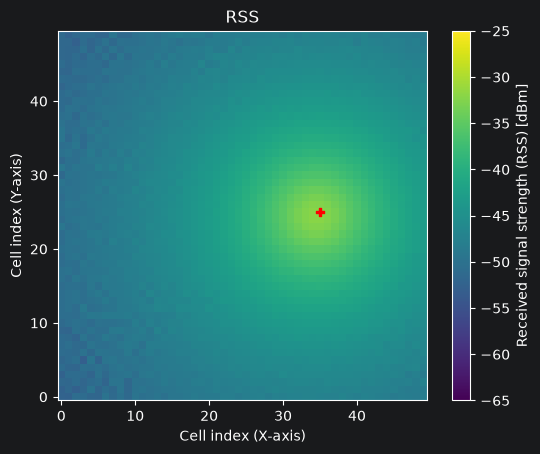

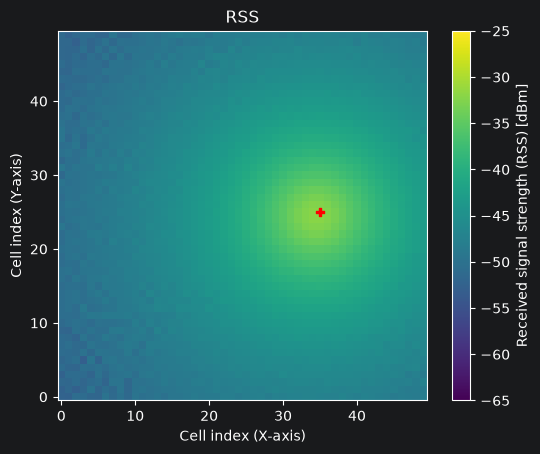

In [21]:
radio_map.show(metric = "rss", vmin = -65, vmax = -25)